Bài tập hướng dẫn

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
iris = load_iris()
X = iris['data'] # Các đặc trưng (features)
y = iris['target'] # Các nhãn (target)
X = X[y != 2] # Loại bỏ lớp 2
y = y[y != 2] # Chỉ giữ lại lớp 0 và 1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
print(f"Độ chính xác (Accuracy): {accuracy}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("Báo cáo phân loại (Classification Report):")
print(class_report)

Độ chính xác (Accuracy): 1.0
Ma trận nhầm lẫn (Confusion Matrix):
[[12  0]
 [ 0  8]]
Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



Bài tập ở lớp:
Bài 1


Hệ số góc (đơn giá ước lượng/m2): 30.29 triệu VND/m2
Hệ số chặn (sai số cố định): 492.94 triệu VND
Sai số bình phương trung bình (MSE): 97616.15
Hệ số xác định R2-score: 0.8918


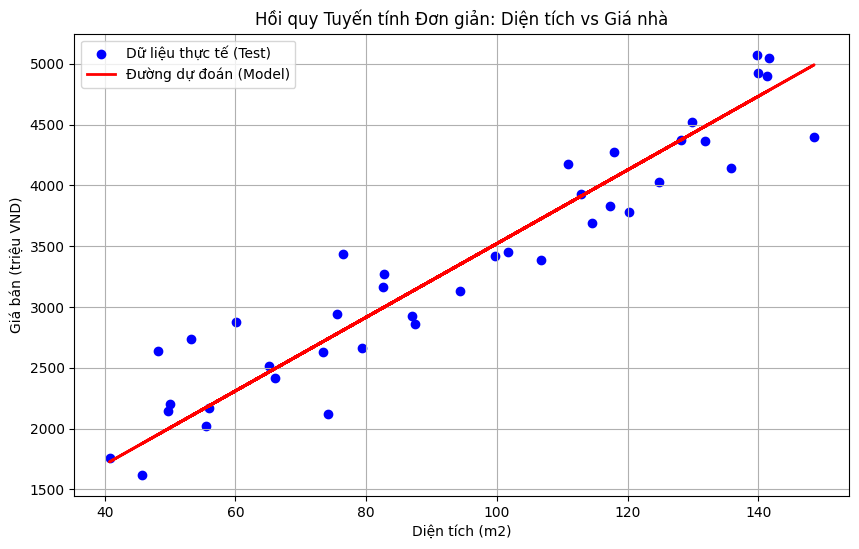

In [14]:
import numpy as np # Thư viện toán học và xử lý mảng
import matplotlib.pyplot as plt # Thư viện để vẽ biểu đồ
from sklearn.linear_model import LinearRegression # Import thuật toán Hồi quy tuyến tính từ sklearn
from sklearn.model_selection import train_test_split # Hàm chia dữ liệu train/test
from sklearn.metrics import mean_squared_error, r2_score # Các chỉ số đánh giá mô hình

# 1. Tạo dữ liệu giả định
np.random.seed(42) # Thiết lập seed để kết quả ngẫu nhiên có thể tái lập
n_samples = 200 # Số lượng mẫu dữ liệu

# Diện tích nhà ngẫu nhiên từ 30m2 đến 150m2
X_simple = np.random.uniform(40, 150, (n_samples, 1))

# Giả định giá thực tế = 30 triệu/m2 + thêm một lượng nhiễu (noise) ngẫu nhiên để tăng tính thực tế
noise = np.random.normal(0, 300, (n_samples, 1)) # Nhiễu với độ lệch chuẩn là 300 triệu
y_simple = 30 * X_simple + 500 + noise # Phương trình: Giá = 30 * Diện tích + 500 + Nhiễu

# 2. Chia dữ liệu thành tập huấn luyện (80%) và tập kiểm tra (20%)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_simple, y_simple,
                                                            test_size=0.2, random_state=42)

# 3. Khởi tạo và huấn luyện mô hình hồi quy tuyến tính
simple_model = LinearRegression() # Tạo đối tượng mô hình
simple_model.fit(X_train_s, y_train_s) # Huấn luyện mô hình trên tập train

# 4. Dự đoán trên tập kiểm tra
y_pred_s = simple_model.predict(X_test_s)

# 5. Đánh giá mô hình
mse = mean_squared_error(y_test_s, y_pred_s) # Tính sai số bình phương trung bình
r2 = r2_score(y_test_s, y_pred_s) # Tính hệ số xác định R-squared

print(f"Hệ số góc (đơn giá ước lượng/m2): {simple_model.coef_[0][0]:.2f} triệu VND/m2")
print(f"Hệ số chặn (sai số cố định): {simple_model.intercept_[0]:.2f} triệu VND")
print(f"Sai số bình phương trung bình (MSE): {mse:.2f}")
print(f"Hệ số xác định R2-score: {r2:.4f}")

# 6. Vẽ biểu đồ trực quan hóa kết quả
plt.figure(figsize=(10, 6)) # Khởi tạo kích thước khung hình
plt.scatter(X_test_s, y_test_s, color='blue', label='Dữ liệu thực tế (Test)') # Vẽ các điểm dữ liệu thực tế
plt.plot(X_test_s, y_pred_s, color='red', linewidth=2, label='Đường dự đoán (Model)') # Vẽ đường hồi quy
plt.title('Hồi quy Tuyến tính Đơn giản: Diện tích vs Giá nhà') # Đặt tên biểu đồ
plt.xlabel('Diện tích (m2)') # Đặt tên trục X
plt.ylabel('Giá bán (triệu VND)') # Đặt tên trục Y
plt.legend() # Hiển thị chú thích
plt.grid(True) # Hiển thị lưới tọa độ
plt.show() # Trực quan biểu đồ

=== Kết quả mô hình hồi quy đa biến ===
Hệ số cho Diện tích (m2): 24.86
Hệ số cho Số phòng ngủ: 143.39
Hệ số cho Khoảng cách (km): -39.09
Hệ số cho Tuổi nhà (năm): -9.60
Hệ số chặn: 621.45
R2-score của mô hình đa biến: 0.9862


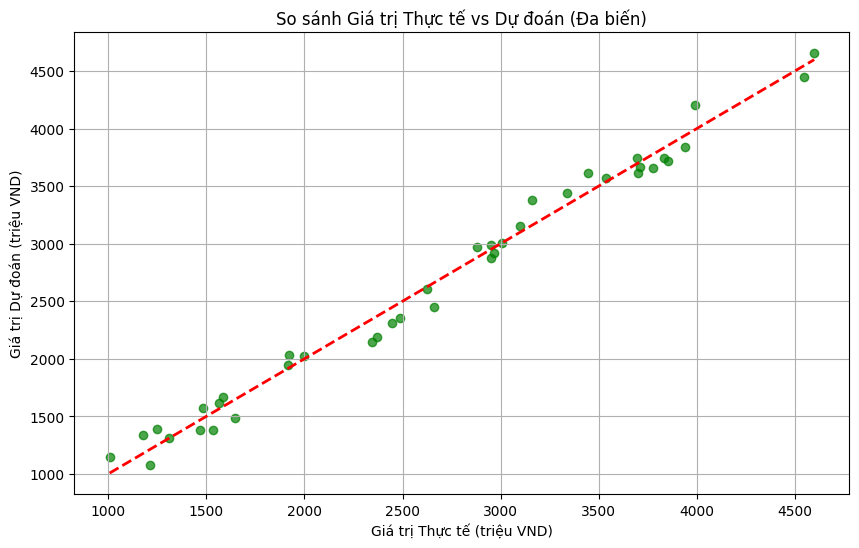

In [4]:
# 1. Tạo các đặc trưng mới cho 200 mẫu nhà
# Số phòng ngủ: ngẫu nhiên từ 1 đến 5 phòng
bedrooms = np.random.randint(1, 6, size=(n_samples, 1))

# Khoảng cách đến trung tâm thành phố: từ 1 đến 20 km
distance = np.random.uniform(1, 20, size=(n_samples, 1))

# Tuổi đời của nhà: từ 0 (nhà mới) đến 30 năm
house_age = np.random.uniform(0, 30, size=(n_samples, 1))

# Ghép tất cả các đặc trưng lại thành một ma trận đầu vào X đa biến
# Bao gồm: Diện tích, Số phòng ngủ, Khoảng cách, Tuổi nhà
X_multi = np.hstack((X_simple, bedrooms, distance, house_age))

# 2. Tạo nhãn Giá bán mới chịu ảnh hưởng bởi tất cả các yếu tố trên
# Giá = 25*DiệnTích + 150*SốPhòngNgủ - 40*KhoảngCách - 10*TuổiNhà + 600 + Nhiễu
y_multi = (25 * X_simple
           + 150 * bedrooms
           - 40 * distance
           - 10 * house_age
           + 600
           + np.random.normal(0, 150, (n_samples, 1))) # Thêm nhiễu ngẫu nhiên

# 3. Chia tập dữ liệu đa biến thành Train và Test
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

# 4. Huấn luyện mô hình đa biến
multi_model = LinearRegression() # Khởi tạo mô hình
multi_model.fit(X_train_m, y_train_m) # Huấn luyện mô hình đa biến

# 5. Dự đoán trên tập kiểm tra
y_pred_m = multi_model.predict(X_test_m)

# 6. Đánh giá và in các hệ số của mô hình
print("=== Kết quả mô hình hồi quy đa biến ===")
print(f"Hệ số cho Diện tích (m2): {multi_model.coef_[0][0]:.2f}")
print(f"Hệ số cho Số phòng ngủ: {multi_model.coef_[0][1]:.2f}")
print(f"Hệ số cho Khoảng cách (km): {multi_model.coef_[0][2]:.2f}")
print(f"Hệ số cho Tuổi nhà (năm): {multi_model.coef_[0][3]:.2f}")
print(f"Hệ số chặn: {multi_model.intercept_[0]:.2f}")
print(f"R2-score của mô hình đa biến: {r2_score(y_test_m, y_pred_m):.4f}")

# 7. So sánh thực tế và dự đoán bằng biểu đồ
plt.figure(figsize=(10, 6))
plt.scatter(y_test_m, y_pred_m, color='green', alpha=0.7) # Vẽ biểu đồ phân tán so sánh
plt.plot([y_test_m.min(), y_test_m.max()], [y_test_m.min(), y_test_m.max()], 'r--', lw=2) # Đường chéo hoàn hảo 45 độ
plt.title('So sánh Giá trị Thực tế vs Dự đoán (Đa biến)')
plt.xlabel('Giá trị Thực tế (triệu VND)')
plt.ylabel('Giá trị Dự đoán (triệu VND)')
plt.grid(True)
plt.show()

Bài tập ở lớp : Bài 2


In [19]:
import numpy as np # Thư viện toán học để tạo dữ liệu ngẫu nhiên
import pandas as pd # Thư viện xử lý bảng dữ liệu
import matplotlib.pyplot as plt # Thư viện vẽ biểu đồ

# Thiết lập seed ngẫu nhiên để kết quả chạy không đổi
np.random.seed(42)
n_samples = 300 # Tạo 300 mẫu bệnh nhân

# Tạo ngẫu nhiên chỉ số BMI từ 15 đến 40
bmi_data = np.random.uniform(15, 40, (n_samples, 1))

# TĂNG ĐỘ NHIỄU: Giảm hệ số góc từ 0.4 xuống 0.1 để làm giảm mối liên hệ tuyến tính giữa BMI và bệnh tật
# Điều này làm tăng sự chồng lấn giữa các mẫu bị bệnh và không bị bệnh (tương đương với tăng độ nhiễu)
logits = 0.12 * (bmi_data - 25) # Hệ số nhỏ hơn làm tăng sự bất định (nhiễu)
probabilities = 1 / (1 + np.exp(-logits)) # Chuyển đổi sang xác suất từ 0 đến 1 bằng hàm Sigmoid

# Tạo nhãn mắc bệnh (1: Mắc bệnh, 0: Khỏe mạnh) dựa trên xác suất mới đã bị làm nhiễu
disease_labels = np.random.binomial(1, probabilities).ravel()

# Chuyển đổi dữ liệu thành DataFrame để dễ quản lý
df_patients = pd.DataFrame({
    'BMI': bmi_data.ravel(),
    'Mac_Benh': disease_labels
})

# Hiển thị 5 dòng dữ liệu đầu tiên
display(df_patients.head())

,BMI,Mac_Benh
0,24.363503,0
1,38.767858,1
2,33.299849,1
3,29.966462,1
4,18.900466,1


In [6]:
from sklearn.model_selection import train_test_split # Hàm chia tập dữ liệu train/test
from sklearn.linear_model import LogisticRegression # Import thuật toán Hồi quy Logistic
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report # Các độ đo đánh giá

# Chia dữ liệu thành các biến độc lập X (BMI) và biến phụ thuộc y (Mắc bệnh)
X = df_patients[['BMI']]
y = df_patients['Mac_Benh']

# Phân chia dữ liệu thành tập huấn luyện (80%) và tập kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Khởi tạo mô hình Hồi quy Logistic
logistic_model = LogisticRegression()

# Huấn luyện mô hình trên tập dữ liệu train
logistic_model.fit(X_train, y_train)

# Dự đoán nhãn mắc bệnh (0 hoặc 1) trên tập dữ liệu test
y_pred = logistic_model.predict(X_test)

# Dự đoán xác suất mắc bệnh (khoảng giá trị từ 0 đến 1)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Đánh giá hiệu quả mô hình
accuracy = accuracy_score(y_test, y_pred) # Tính độ chính xác tổng quan
conf_mat = confusion_matrix(y_test, y_pred) # Tạo ma trận nhầm lẫn
class_rep = classification_report(y_test, y_pred) # Báo cáo chi tiết Precision, Recall, F1-score

# In kết quả đánh giá
print(f"Độ chính xác của mô hình trên tập Test: {accuracy * 100:.2f}%")
print("\nMa trận nhầm lẫn (Confusion Matrix):")
print(conf_mat)
print("\nBáo cáo phân loại chi tiết:")
print(class_rep)

Độ chính xác của mô hình trên tập Test: 81.67%

Ma trận nhầm lẫn (Confusion Matrix):
[[16  3]
 [ 8 33]]

Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

           0       0.67      0.84      0.74        19
           1       0.92      0.80      0.86        41

    accuracy                           0.82        60
   macro avg       0.79      0.82      0.80        60
weighted avg       0.84      0.82      0.82        60



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


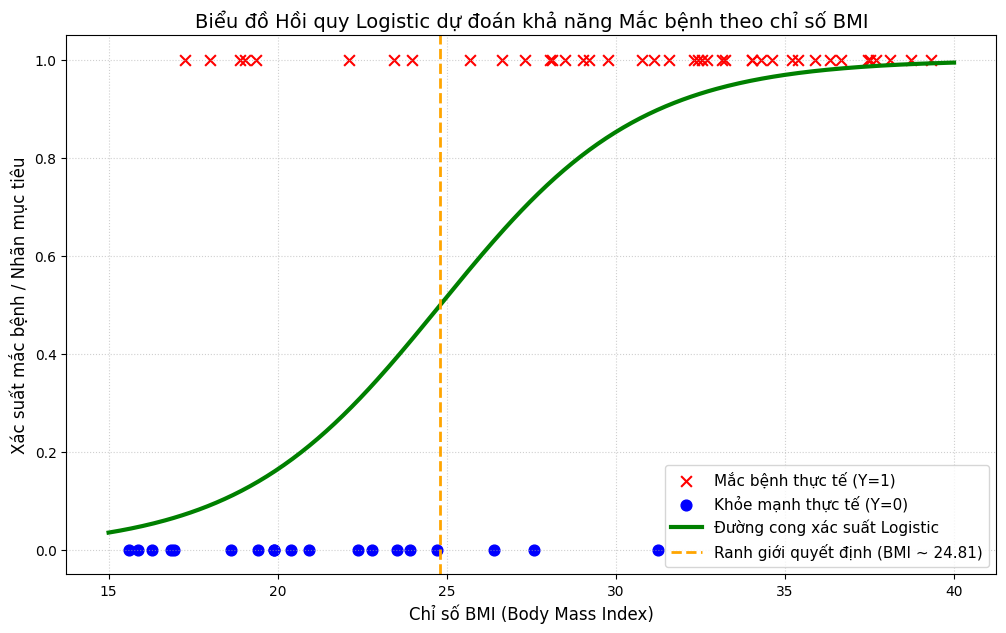

In [7]:
# Tạo một chuỗi liên tục các giá trị BMI từ 15 đến 40 để vẽ đường sigmoid mượt mà
X_curve = np.linspace(15, 40, 300).reshape(-1, 1)

# Dự đoán xác suất mắc bệnh tương ứng với chuỗi BMI trên
y_curve_prob = logistic_model.predict_proba(X_curve)[:, 1]

# Bắt đầu vẽ biểu đồ
plt.figure(figsize=(12, 7))

# Vẽ các điểm dữ liệu thực tế của tập kiểm tra (Test set)
plt.scatter(X_test[y_test == 1], y_test[y_test == 1], color='red', marker='x', s=60, label='Mắc bệnh thực tế (Y=1)')
plt.scatter(X_test[y_test == 0], y_test[y_test == 0], color='blue', marker='o', s=60, label='Khỏe mạnh thực tế (Y=0)')

# Vẽ đường cong hồi quy Logistic đại diện cho xác suất dự báo
plt.plot(X_curve, y_curve_prob, color='green', linewidth=3, label='Đường cong xác suất Logistic')

# Vẽ đường ranh giới quyết định (Decision Boundary) tại ngưỡng xác suất 0.5
# Tìm giá trị BMI mà tại đó xác suất đạt 0.5
decision_boundary = -logistic_model.intercept_[0] / logistic_model.coef_[0][0]
plt.axvline(x=decision_boundary, color='orange', linestyle='--', linewidth=2,
            label=f'Ranh giới quyết định (BMI ~ {decision_boundary:.2f})')

# Thiết lập các tiêu đề và nhãn trục
plt.title('Biểu đồ Hồi quy Logistic dự đoán khả năng Mắc bệnh theo chỉ số BMI', fontsize=14)
plt.xlabel('Chỉ số BMI (Body Mass Index)', fontsize=12)
plt.ylabel('Xác suất mắc bệnh / Nhãn mục tiêu', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show() # Hiển thị biểu đồ

 Bài tập về nhà: bài 2


In [22]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Khai báo danh sách các ngưỡng xác suất cần thử nghiệm
thresholds = [0.5, 0.6, 0.7]

# Đảm bảo lấy đúng nhãn test của dữ liệu BMI bệnh nhân từ DataFrame ban đầu
# để tránh việc biến y_test bị ghi đè bởi tập dữ liệu khác
_, X_test_bmi, _, y_test_bmi = train_test_split(
    df_patients[['BMI']], df_patients['Mac_Benh'], test_size=0.2, random_state=42
)

for thresh in thresholds:
    print(f"\n{'='*20} THỬ NGHIỆM VỚI NGƯỠNG: {thresh} {'='*20}")

    # Áp dụng ngưỡng tùy chỉnh lên xác suất dự báo (y_prob)
    y_pred_custom = (y_prob >= thresh).astype(int)

    # Đánh giá lại mô hình dựa trên nhãn thực tế y_test_bmi chính xác
    acc_custom = accuracy_score(y_test_bmi, y_pred_custom)
    conf_custom = confusion_matrix(y_test_bmi, y_pred_custom)

    print(f"Độ chính xác tương ứng: {acc_custom * 100:.2f}%")
    print("Ma trận nhầm lẫn:")
    print(conf_custom)
    print("Báo cáo phân loại chi tiết:")
    print(classification_report(y_test_bmi, y_pred_custom))


==================== THỬ NGHIỆM VỚI NGƯỠNG: 0.5 ====================
Độ chính xác tương ứng: 68.33%
Ma trận nhầm lẫn:
[[12  7]
 [12 29]]
Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

           0       0.50      0.63      0.56        19
           1       0.81      0.71      0.75        41

    accuracy                           0.68        60
   macro avg       0.65      0.67      0.66        60
weighted avg       0.71      0.68      0.69        60


==================== THỬ NGHIỆM VỚI NGƯỠNG: 0.6 ====================
Độ chính xác tương ứng: 66.67%
Ma trận nhầm lẫn:
[[12  7]
 [13 28]]
Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

           0       0.48      0.63      0.55        19
           1       0.80      0.68      0.74        41

    accuracy                           0.67        60
   macro avg       0.64      0.66      0.64        60
weighted avg       0.70      0.67      0.68        60


=============


Bài tập ở lớp: Bài 3


In [8]:
import pandas as pd # Thư viện xử lý dữ liệu dạng bảng
import numpy as np # Thư viện toán học
from sklearn.datasets import fetch_california_housing # Hàm tải bộ dữ liệu giá nhà California

# 1. Tải bộ dữ liệu thực tế
housing = fetch_california_housing(as_frame=True)
df_housing = housing.frame # Chuyển thành cấu trúc DataFrame của Pandas

# 2. Khám phá cấu trúc dữ liệu cơ bản
print("=== Thông tin bộ dữ liệu California Housing ===")
print(df_housing.info()) # Hiển thị các cột, số lượng dòng dữ liệu và kiểu dữ liệu

# Hiển thị 5 dòng đầu tiên để quan sát các đặc trưng thực tế
display(df_housing.head())

=== Thông tin bộ dữ liệu California Housing ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [9]:
from sklearn.model_selection import train_test_split # Hàm chia dữ liệu train/test
from sklearn.ensemble import RandomForestRegressor # Mô hình hồi quy rừng ngẫu nhiên (mạnh mẽ và phổ biến)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error # Các độ đo đánh giá

# 1. Tách đặc trưng đầu vào X và nhãn mục tiêu y (MedHouseVal - Giá nhà trung vị, đơn vị: trăm nghìn USD)
X_real = df_housing.drop(columns=['MedHouseVal'])
y_real = df_housing['MedHouseVal']

# 2. Chia tập dữ liệu thành 80% Train và 20% Test để đánh giá khách quan
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42
)

# 3. Khởi tạo mô hình Random Forest Regressor
# Giới hạn n_estimators=100 và max_depth=15 để mô hình chạy nhanh và tránh quá khớp (overfitting)
regressor_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)

# 4. Huấn luyện mô hình trên tập dữ liệu Train
print("Đang huấn luyện mô hình Random Forest... Vui lòng đợi trong giây lát.")
regressor_model.fit(X_train_r, y_train_r)
print("Đã huấn luyện xong!")

Đang huấn luyện mô hình Random Forest... Vui lòng đợi trong giây lát.
Đã huấn luyện xong!


=== Đánh giá hiệu năng mô hình trên tập Test ===
Sai số bình phương trung bình (MSE): 0.2616
Sai số tuyệt đối trung bình (MAE): 0.3332 (~ 33322 USD)
Hệ số xác định (R2-score): 0.8004 (Mô hình giải thích được 80.04% sự biến động của giá nhà)


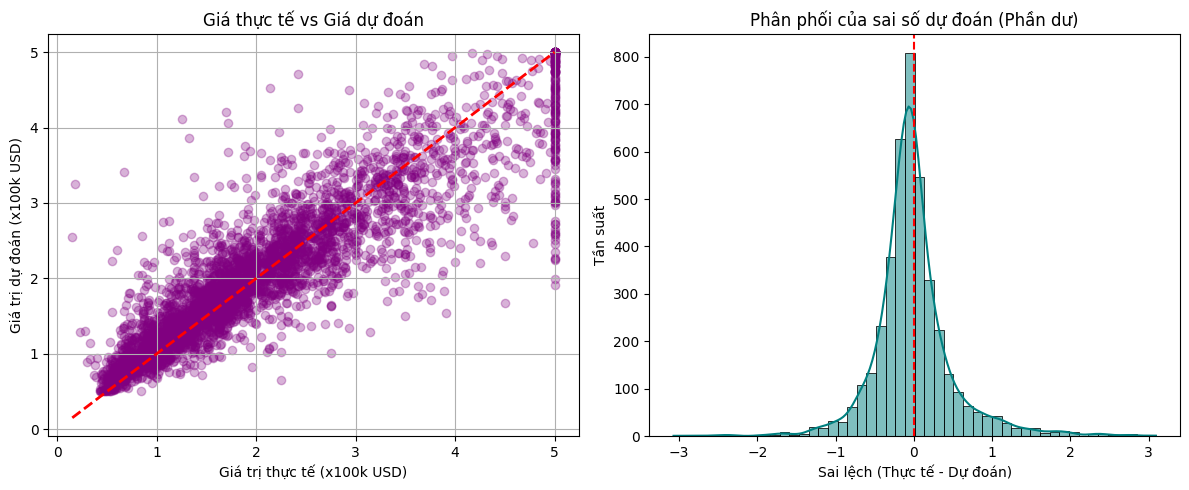

In [18]:
import matplotlib.pyplot as plt # Thư viện vẽ biểu đồ
import seaborn as sns # Thư viện vẽ biểu đồ nâng cao

# 1. Dự đoán giá trị trên tập kiểm tra (Test set)
y_pred_r = regressor_model.predict(X_test_r)

# 2. Tính toán các chỉ số đánh giá hiệu năng
mse_r = mean_squared_error(y_test_r, y_pred_r) # Sai số bình phương trung bình
mae_r = mean_absolute_error(y_test_r, y_pred_r) # Sai số tuyệt đối trung bình
r2_r = r2_score(y_test_r, y_pred_r) # Hệ số xác định R2 (Độ khớp của mô hình)

print("=== Đánh giá hiệu năng mô hình trên tập Test ===")
print(f"Sai số bình phương trung bình (MSE): {mse_r:.4f}")
print(f"Sai số tuyệt đối trung bình (MAE): {mae_r:.4f} (~ {mae_r * 100000:.0f} USD)")
print(f"Hệ số xác định (R2-score): {r2_r:.4f} (Mô hình giải thích được {r2_r*100:.2f}% sự biến động của giá nhà)")

# 3. Trực quan hóa sự phân bố sai số dự đoán
plt.figure(figsize=(12, 5))

# Biểu đồ 1: Biểu đồ phân tán so sánh giữa Giá thực tế và Giá dự đoán
plt.subplot(1, 2, 1)
plt.scatter(y_test_r, y_pred_r, alpha=0.3, color='purple')
plt.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2)
plt.title('Giá thực tế vs Giá dự đoán')
plt.xlabel('Giá trị thực tế (x100k USD)')
plt.ylabel('Giá trị dự đoán (x100k USD)')
plt.grid(True)

# Biểu đồ 2: Phân phối của phần dư (Residuals = Thực tế - Dự đoán)
residuals = y_test_r - y_pred_r
plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='teal', bins=50)
plt.axvline(x=0, color='red', linestyle='--')
plt.title('Phân phối của sai số dự đoán (Phần dư)')
plt.xlabel('Sai lệch (Thực tế - Dự đoán)')
plt.ylabel('Tần suất')

plt.tight_layout()
plt.show()


Bài tập về nhà: Bài 3: Hồi quy tuyến tính (Linear Regression) dự đoán giá nhà California



In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Lựa chọn một số thuộc tính đặc trưng quan trọng
# Chúng ta dùng: MedInc (Thu nhập trung bình), AveRooms (Số phòng trung bình), AveOccup (Số người ở trung bình)
features = ['MedInc', 'AveRooms', 'AveOccup']
X_lr = df_housing[features]
y_lr = df_housing['MedHouseVal']

# 2. Phân chia dữ liệu thành tập huấn luyện (80%) và tập kiểm tra (20%)
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y_lr, test_size=0.2, random_state=42
)

# 3. Khởi tạo và huấn luyện mô hình hồi quy tuyến tính
lr_model = LinearRegression()
lr_model.fit(X_train_lr, y_train_lr)

# 4. Dự đoán kết quả trên tập kiểm tra
y_pred_lr = lr_model.predict(X_test_lr)

# 5. Tính toán các chỉ số đánh giá
mse_lr = mean_squared_error(y_test_lr, y_pred_lr)
r2_lr = r2_score(y_test_lr, y_pred_lr)

# 6. Hiển thị kết quả chi tiết
print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH LINEAR REGRESSION ===")
print(f"Hệ số góc (Coefficients): {lr_model.coef_}")
print(f"Hệ số chặn (Intercept): {lr_model.intercept_:.4f}")
print(f"Sai số bình phương trung bình (MSE): {mse_lr:.4f}")
print(f"Hệ số xác định (R2-score): {r2_lr:.4f}")

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH LINEAR REGRESSION ===
Hệ số góc (Coefficients): [ 0.43688279 -0.04042962 -0.00382602]
Hệ số chặn (Intercept): 0.6081
Sai số bình phương trung bình (MSE): 0.7007
Hệ số xác định (R2-score): 0.4653
